In [1]:
import numpy as np
import pandas as pd

## stage1

In [2]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

graph_path_1 = './result/w_layer/stage1/tuning/bs32_dp0.1_sw1.0/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage1/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage1/tuning/bs32_dp0.1_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

def Signed_Strength_Centrality(graph_path, label_path):
    '''
    Signed Strength Centrality
    '''
    graphs = np.load(graph_path)
    labels = pd.read_csv(label_path).iloc[:, 0].values

    pos = np.maximum(graphs, 0).mean(axis=0)
    neg = np.maximum(-graphs, 0).mean(axis=0)

    np.fill_diagonal(pos, 0)
    np.fill_diagonal(neg, 0)

    n = pos.shape[0] - 1

    P_out = pos.sum(axis=1) / n
    N_out = neg.sum(axis=1) / n

    P_in = pos.sum(axis=0) / n
    N_in = neg.sum(axis=0) / n

    C_out = P_out - N_out**2 / (P_out + N_out + 1e-9)
    C_in = P_in - N_in**2 / (P_in + N_in + 1e-9)

    centrality = (C_out + C_in) / 2

    return pd.Series(centrality, index=labels)

mean_dc_1 = Signed_Strength_Centrality(graph_path_1, label_path_1)
mean_dc_2 = Signed_Strength_Centrality(graph_path_2, label_path_2)

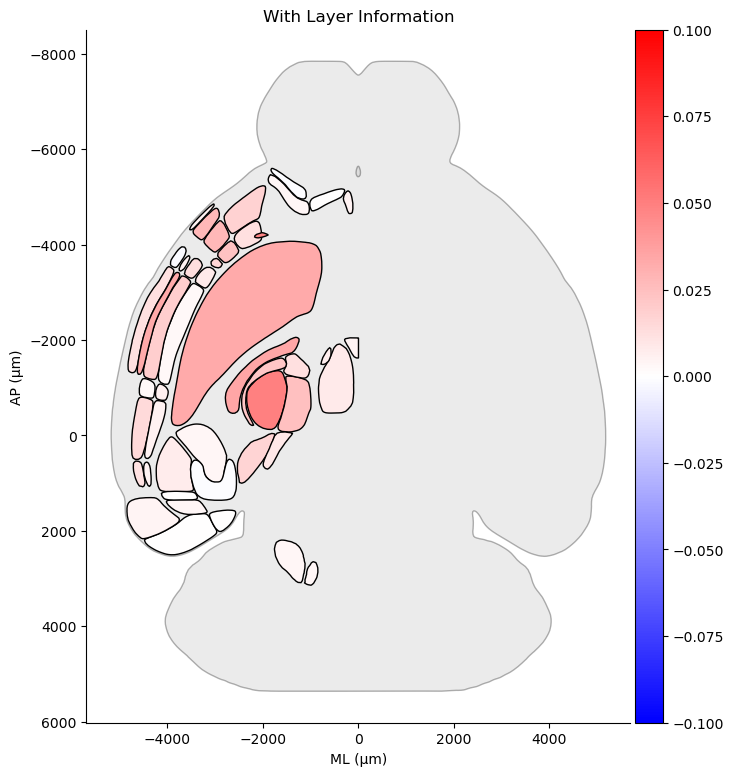

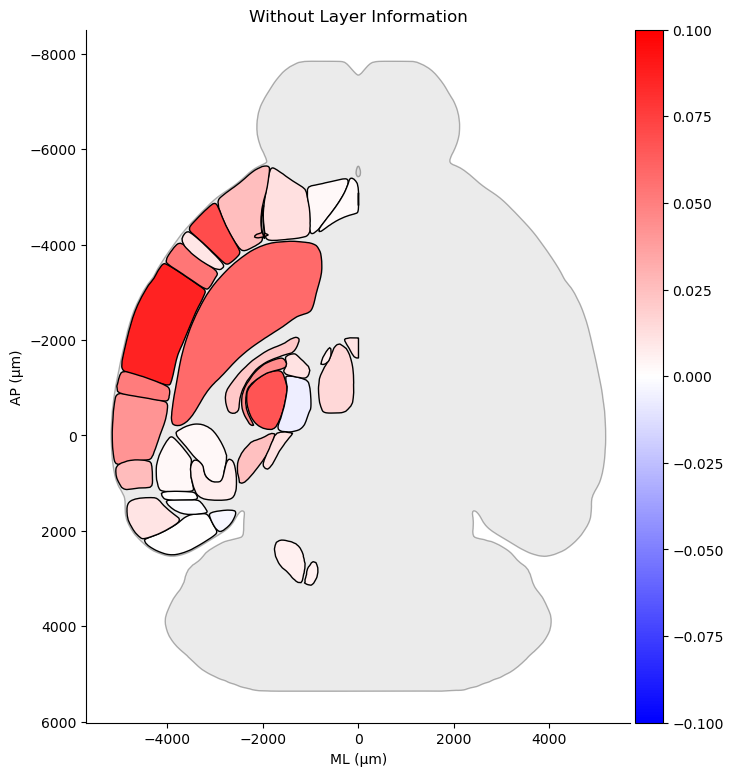

In [3]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh

values1 = mean_dc_1.to_dict()
values2 = mean_dc_2.to_dict()

vmin = -0.1
vmax = 0.1

fig = bgh.Heatmap(
    values=values1,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="With Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

fig = bgh.Heatmap(
    values=values2,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="Without Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

r = 0.499, p = 1.844e-06, MAE = 0.0133


/tmp/ipykernel_2390752/317905381.py:54: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=25)


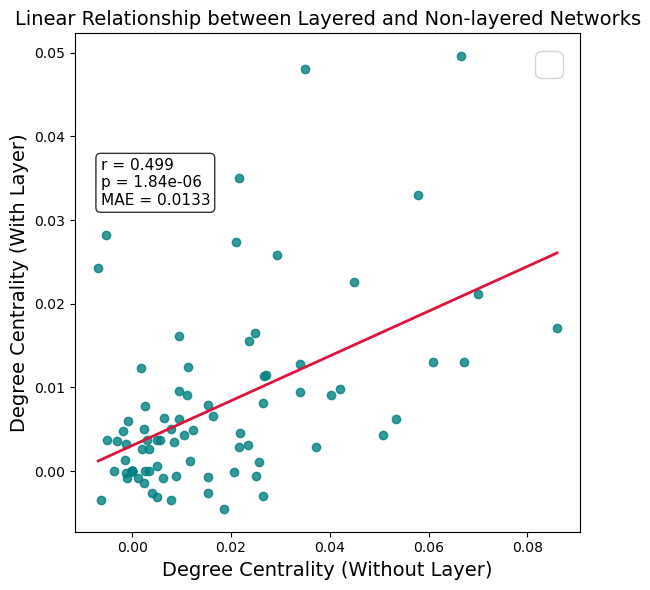

In [4]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import brainglobe_heatmap as bgh
from scipy.stats import linregress
from scipy.stats import spearmanr

w_layer = mean_dc_1.copy()
wo_layer = mean_dc_2.copy()


def get_base_region(name):
    df = pd.read_csv("../data/region_map.csv", sep="\t")
    region_dict = dict(zip(df.iloc[:,0], df.iloc[:,1]))
    return region_dict.get(name, name)

grouped = {}
for region, val in w_layer.items():
    base = get_base_region(region)
    grouped.setdefault(base, []).append(val)

layer_mean = {base: np.nanmean(vals) for base, vals in grouped.items()}
layer_mean = pd.Series(layer_mean)

common_regions = sorted(set(layer_mean.index) & set(wo_layer.index))
aligned_w = layer_mean[common_regions]
aligned_wo = wo_layer[common_regions]


r, p = pearsonr(aligned_w, aligned_wo)
mae = np.mean(np.abs(aligned_w - aligned_wo))
print(f"r = {r:.3f}, p = {p:.3e}, MAE = {mae:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(aligned_wo, aligned_w, color="teal", alpha=0.8, label="")

slope, intercept, r_val, p_val, stderr = linregress(aligned_wo, aligned_w)

x_fit = np.linspace(aligned_wo.min(), aligned_wo.max(), 100)
y_fit = slope * x_fit + intercept
plt.plot(x_fit, y_fit, color="crimson", linewidth=2, label="")

plt.xlabel("Degree Centrality (Without Layer)", fontsize=14)
plt.ylabel("Degree Centrality (With Layer)", fontsize=14)
plt.title("Linear Relationship between Layered and Non-layered Networks", fontsize=14)

text_str = f"r = {r:.3f}\np = {p:.2e}\nMAE = {mae:.4f}"
plt.text(0.05, 0.75, text_str, transform=plt.gca().transAxes,
         fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.legend(fontsize=25)
plt.grid(alpha=0)
plt.tight_layout()
plt.savefig("./result/fig/scatter_with_vs_without_layer_stage1.png", dpi=300, bbox_inches="tight")

plt.show()

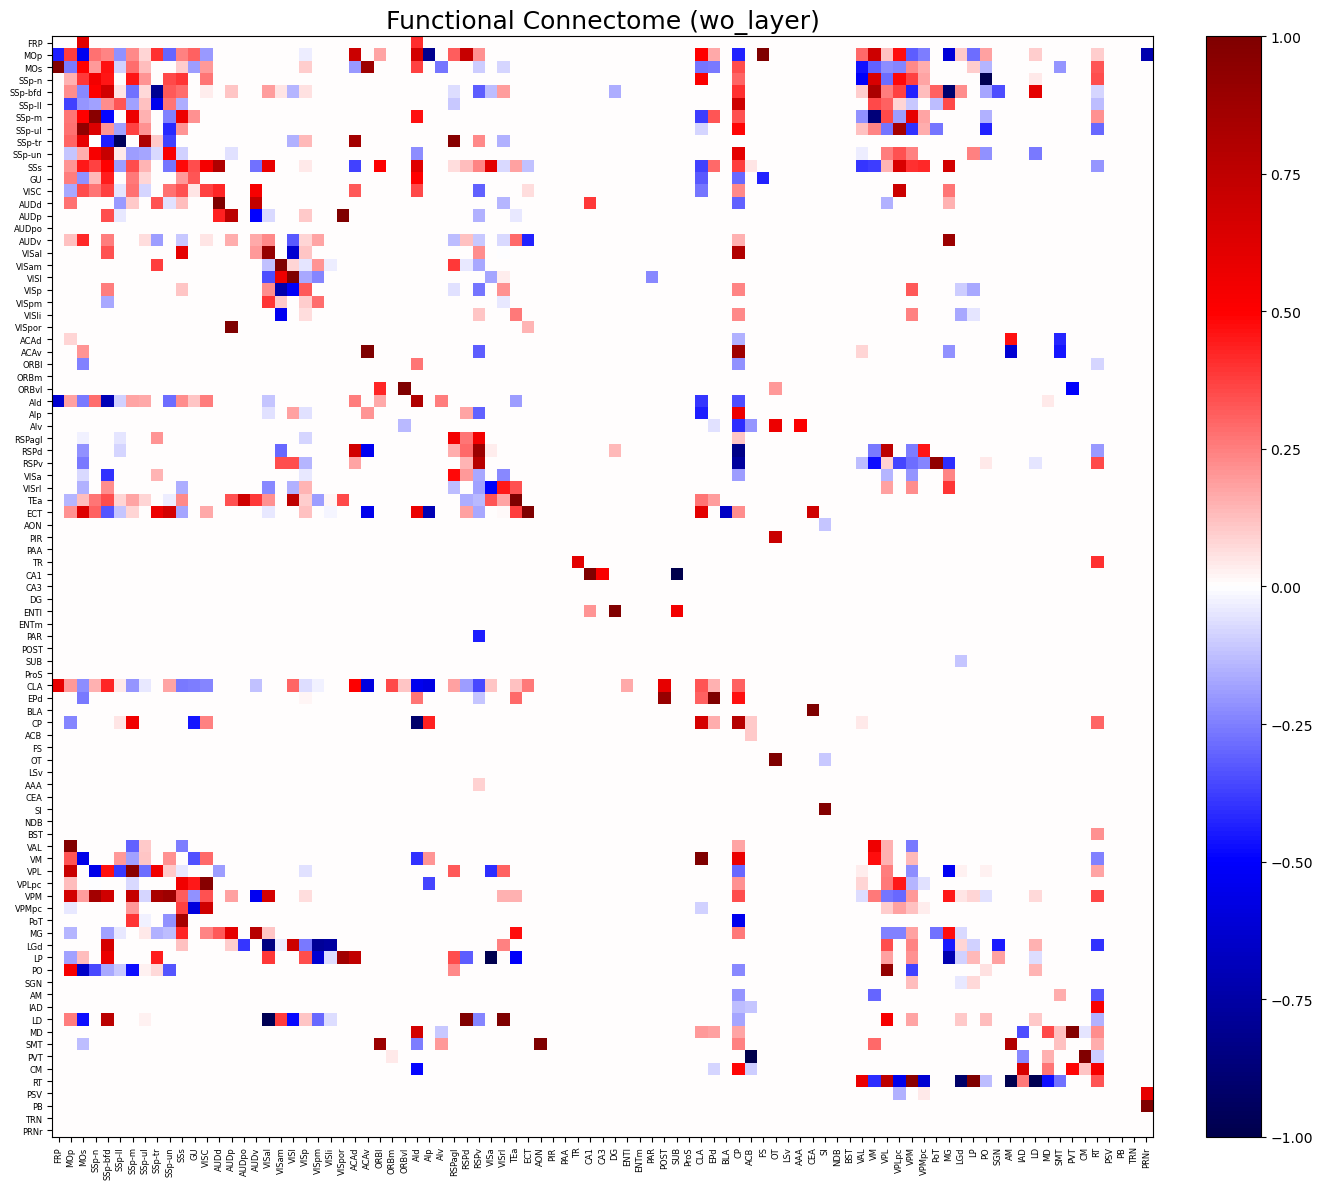

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_2)
df = pd.read_csv(label_path_2)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (wo_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=6)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=6)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_wo_layer_stage1.jpg", format="jpg", dpi=300)
plt.show()


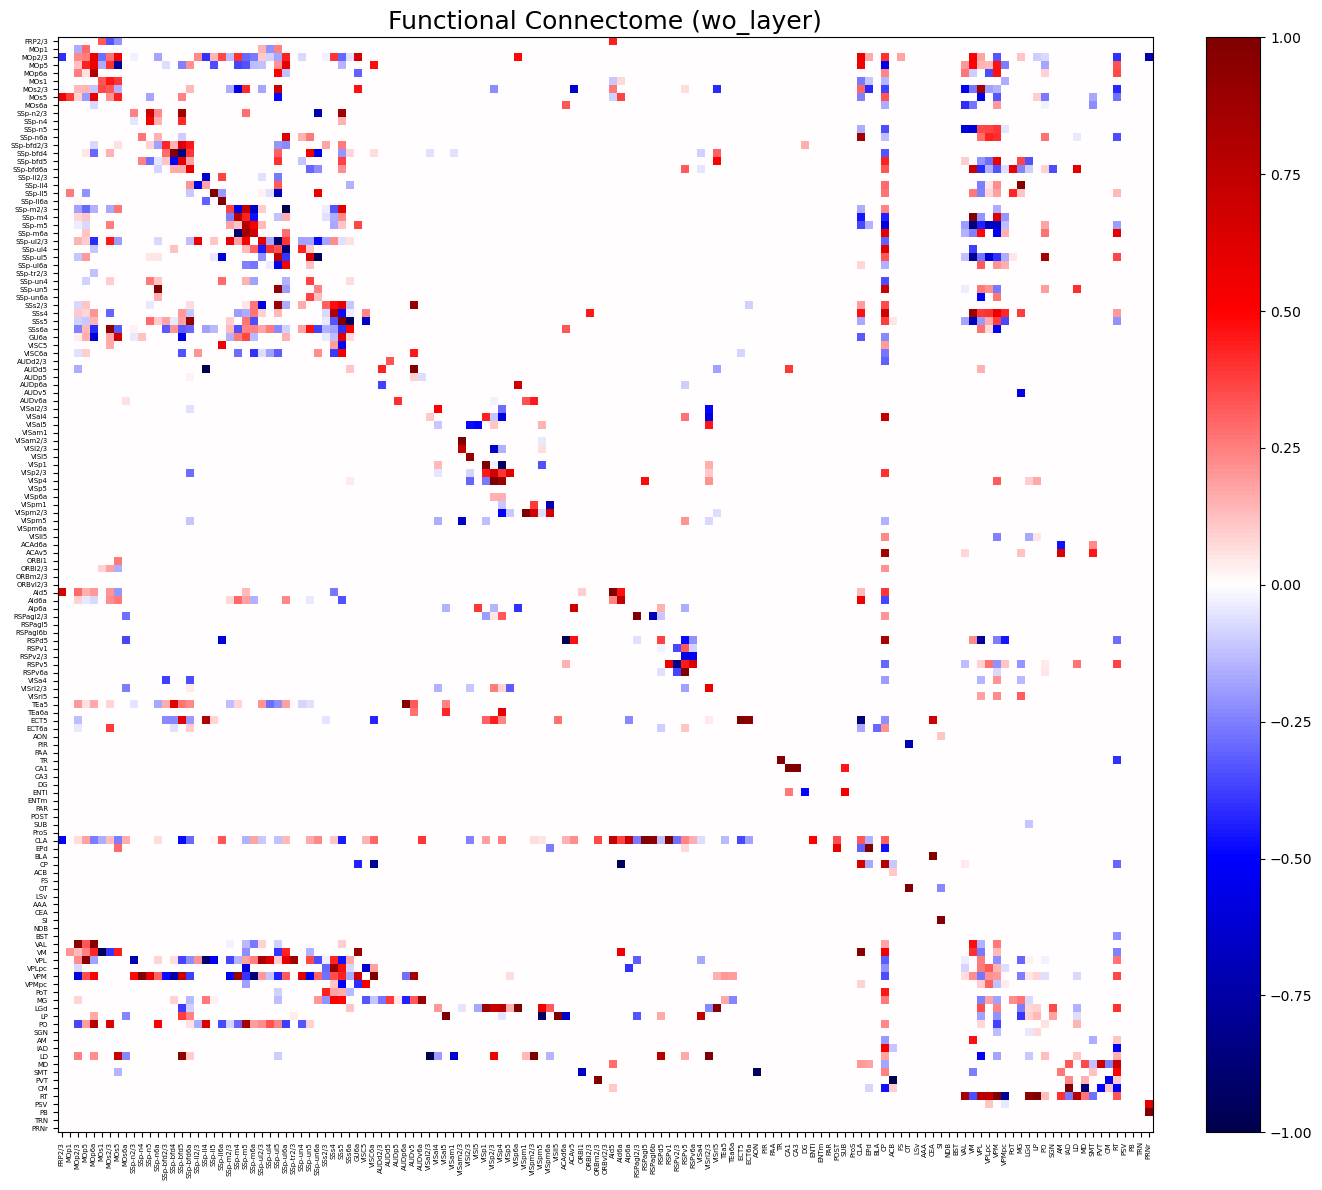

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_1)
df = pd.read_csv(label_path_1)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (wo_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=5)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=5)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_w_layer_stage1.jpg", format="jpg", dpi=300)
plt.show()


## stage2

In [7]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

graph_path_1 = './result/w_layer/stage2/tuning/bs16_dp0.1_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage1/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage2/tuning/bs32_dp0.1_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

def Signed_Strength_Centrality(graph_path, label_path):
    '''
    Signed Strength Centrality
    '''
    graphs = np.load(graph_path)
    labels = pd.read_csv(label_path).iloc[:, 0].values

    pos = np.maximum(graphs, 0).mean(axis=0)
    neg = np.maximum(-graphs, 0).mean(axis=0)

    np.fill_diagonal(pos, 0)
    np.fill_diagonal(neg, 0)

    n = pos.shape[0] - 1

    P_out = pos.sum(axis=1) / n
    N_out = neg.sum(axis=1) / n

    P_in = pos.sum(axis=0) / n
    N_in = neg.sum(axis=0) / n

    C_out = P_out - N_out**2 / (P_out + N_out + 1e-9)
    C_in = P_in - N_in**2 / (P_in + N_in + 1e-9)

    centrality = (C_out + C_in) / 2

    return pd.Series(centrality, index=labels)

mean_dc_1 = Signed_Strength_Centrality(graph_path_1, label_path_1)
mean_dc_2 = Signed_Strength_Centrality(graph_path_2, label_path_2)

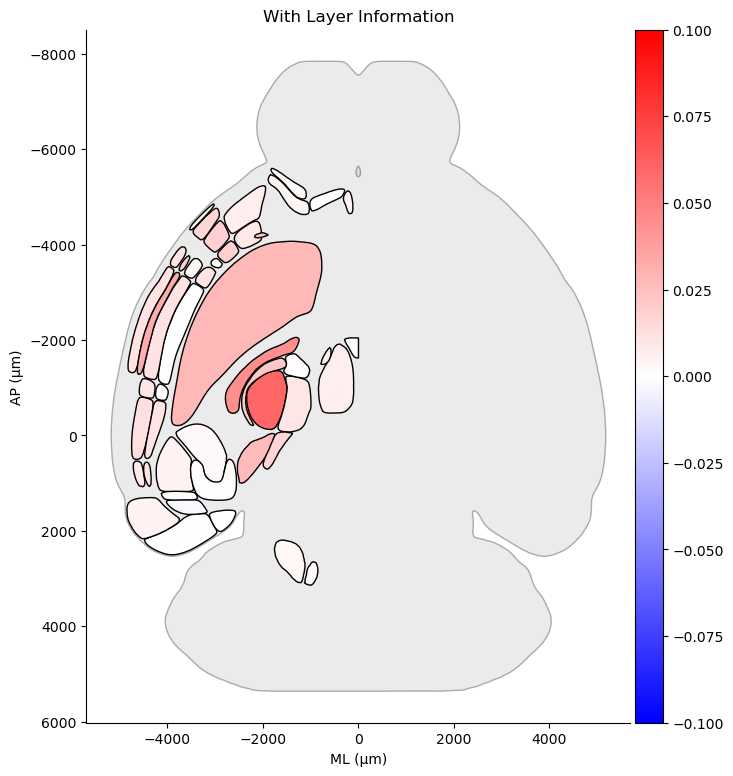

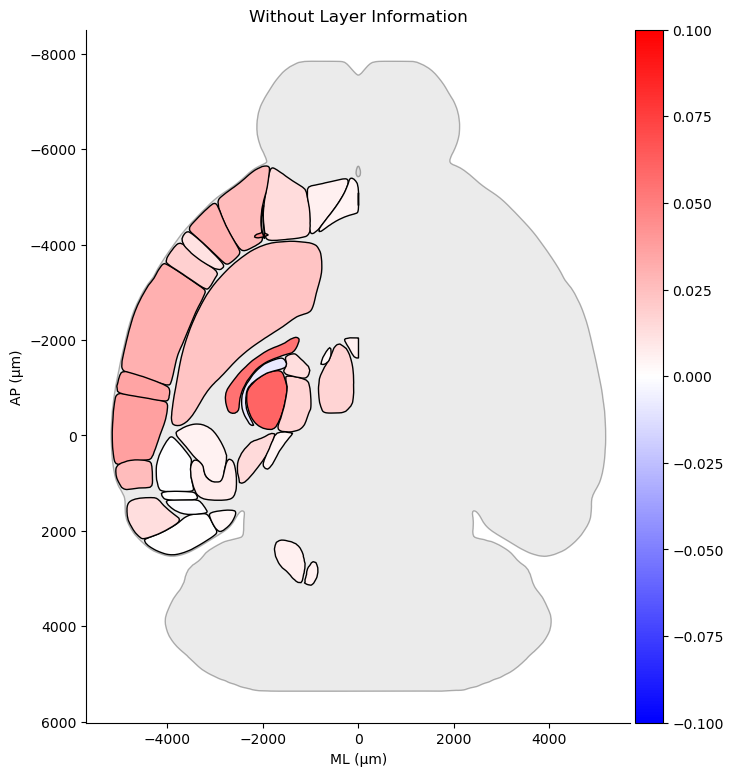

In [8]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh

values1 = mean_dc_1.to_dict()
values2 = mean_dc_2.to_dict()

vmin = -0.1
vmax = 0.1

fig = bgh.Heatmap(
    values=values1,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="With Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

fig = bgh.Heatmap(
    values=values2,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="Without Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

r = 0.513, p = 8.141e-07, MAE = 0.0113


/tmp/ipykernel_2390752/3672927345.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=25)


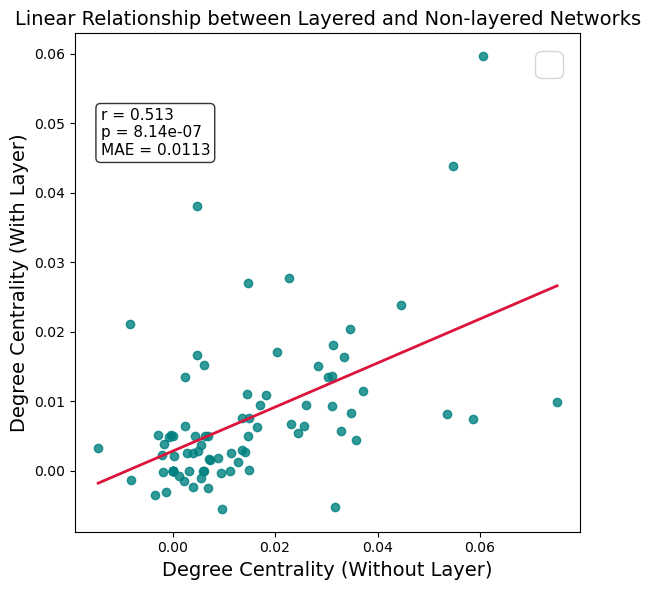

In [9]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import brainglobe_heatmap as bgh
from scipy.stats import linregress

w_layer = mean_dc_1.copy()
wo_layer = mean_dc_2.copy()


def get_base_region(name):
    df = pd.read_csv("../data/region_map.csv", sep="\t")
    region_dict = dict(zip(df.iloc[:,0], df.iloc[:,1]))
    return region_dict.get(name, name)

grouped = {}
for region, val in w_layer.items():
    base = get_base_region(region)
    grouped.setdefault(base, []).append(val)

layer_mean = {base: np.nanmean(vals) for base, vals in grouped.items()}
layer_mean = pd.Series(layer_mean)

common_regions = sorted(set(layer_mean.index) & set(wo_layer.index))
aligned_w = layer_mean[common_regions]
aligned_wo = wo_layer[common_regions]


r, p = pearsonr(aligned_w, aligned_wo)
mae = np.mean(np.abs(aligned_w - aligned_wo))
print(f"r = {r:.3f}, p = {p:.3e}, MAE = {mae:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(aligned_wo, aligned_w, color="teal", alpha=0.8, label="")

slope, intercept, r_val, p_val, stderr = linregress(aligned_wo, aligned_w)

x_fit = np.linspace(aligned_wo.min(), aligned_wo.max(), 100)
y_fit = slope * x_fit + intercept
plt.plot(x_fit, y_fit, color="crimson", linewidth=2, label="")

plt.xlabel("Degree Centrality (Without Layer)", fontsize=14)
plt.ylabel("Degree Centrality (With Layer)", fontsize=14)
plt.title("Linear Relationship between Layered and Non-layered Networks", fontsize=14)

text_str = f"r = {r:.3f}\np = {p:.2e}\nMAE = {mae:.4f}"
plt.text(0.05, 0.85, text_str, transform=plt.gca().transAxes,
         fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.legend(fontsize=25)
plt.grid(alpha=0)
plt.tight_layout()
plt.savefig("./result/fig/scatter_with_vs_without_layer_stage2.png", dpi=300, bbox_inches="tight")

plt.show()


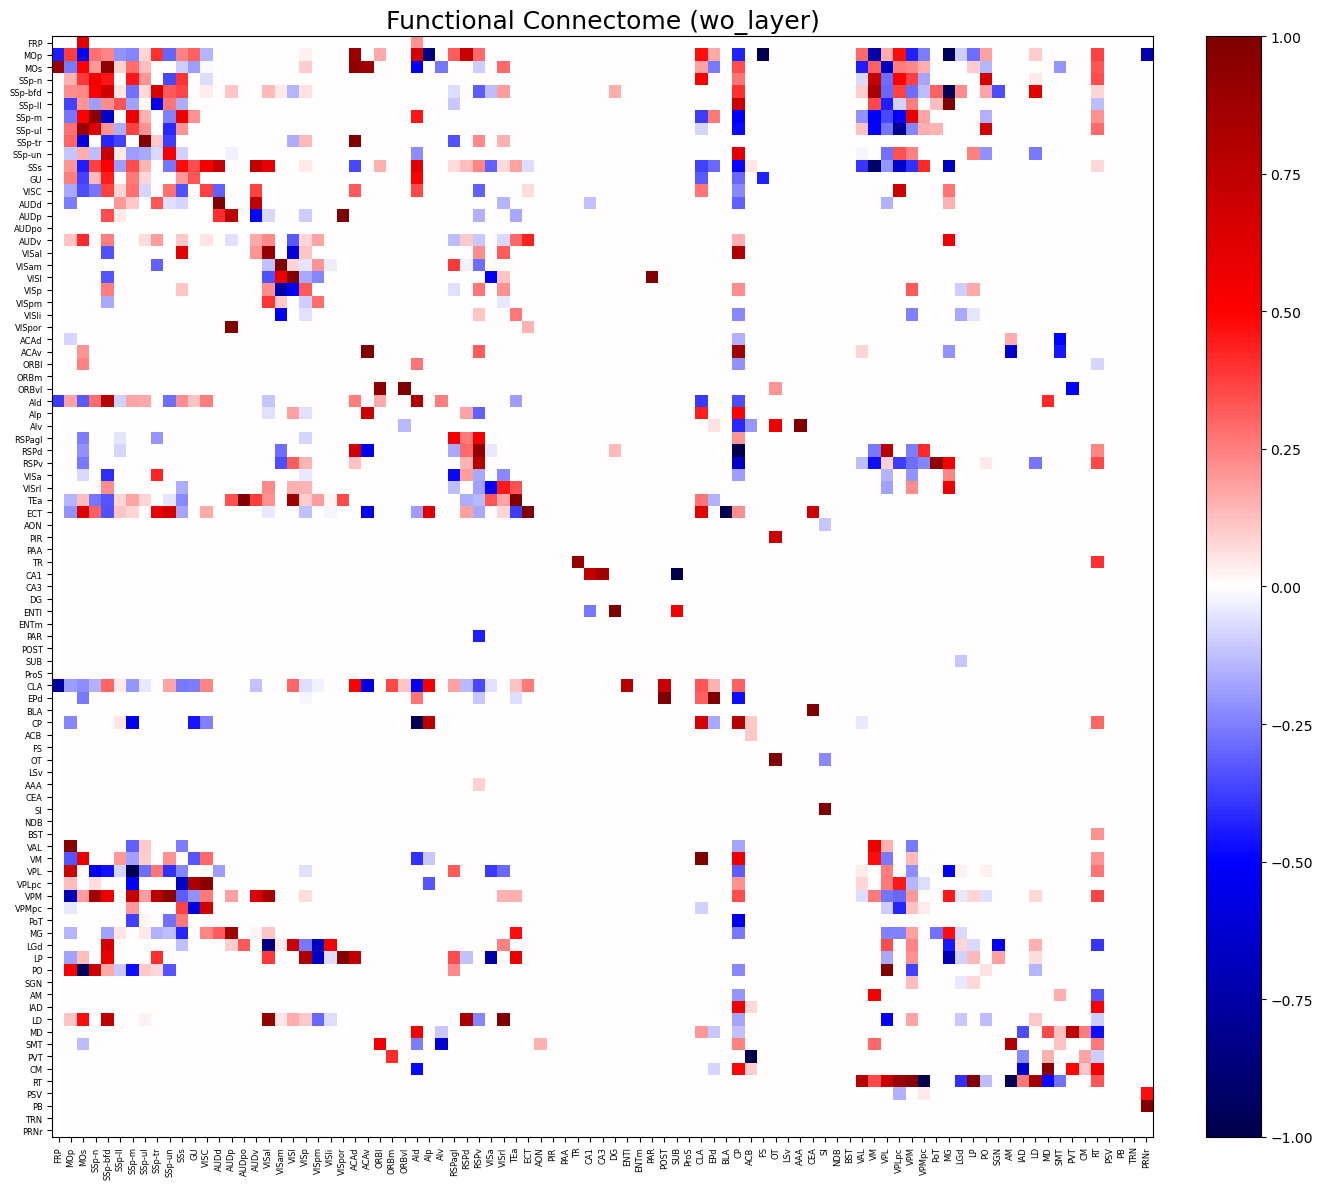

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_2)
df = pd.read_csv(label_path_2)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (wo_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=6)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=6)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_wo_layer_stage2.jpg", format="jpg", dpi=300)
plt.show()


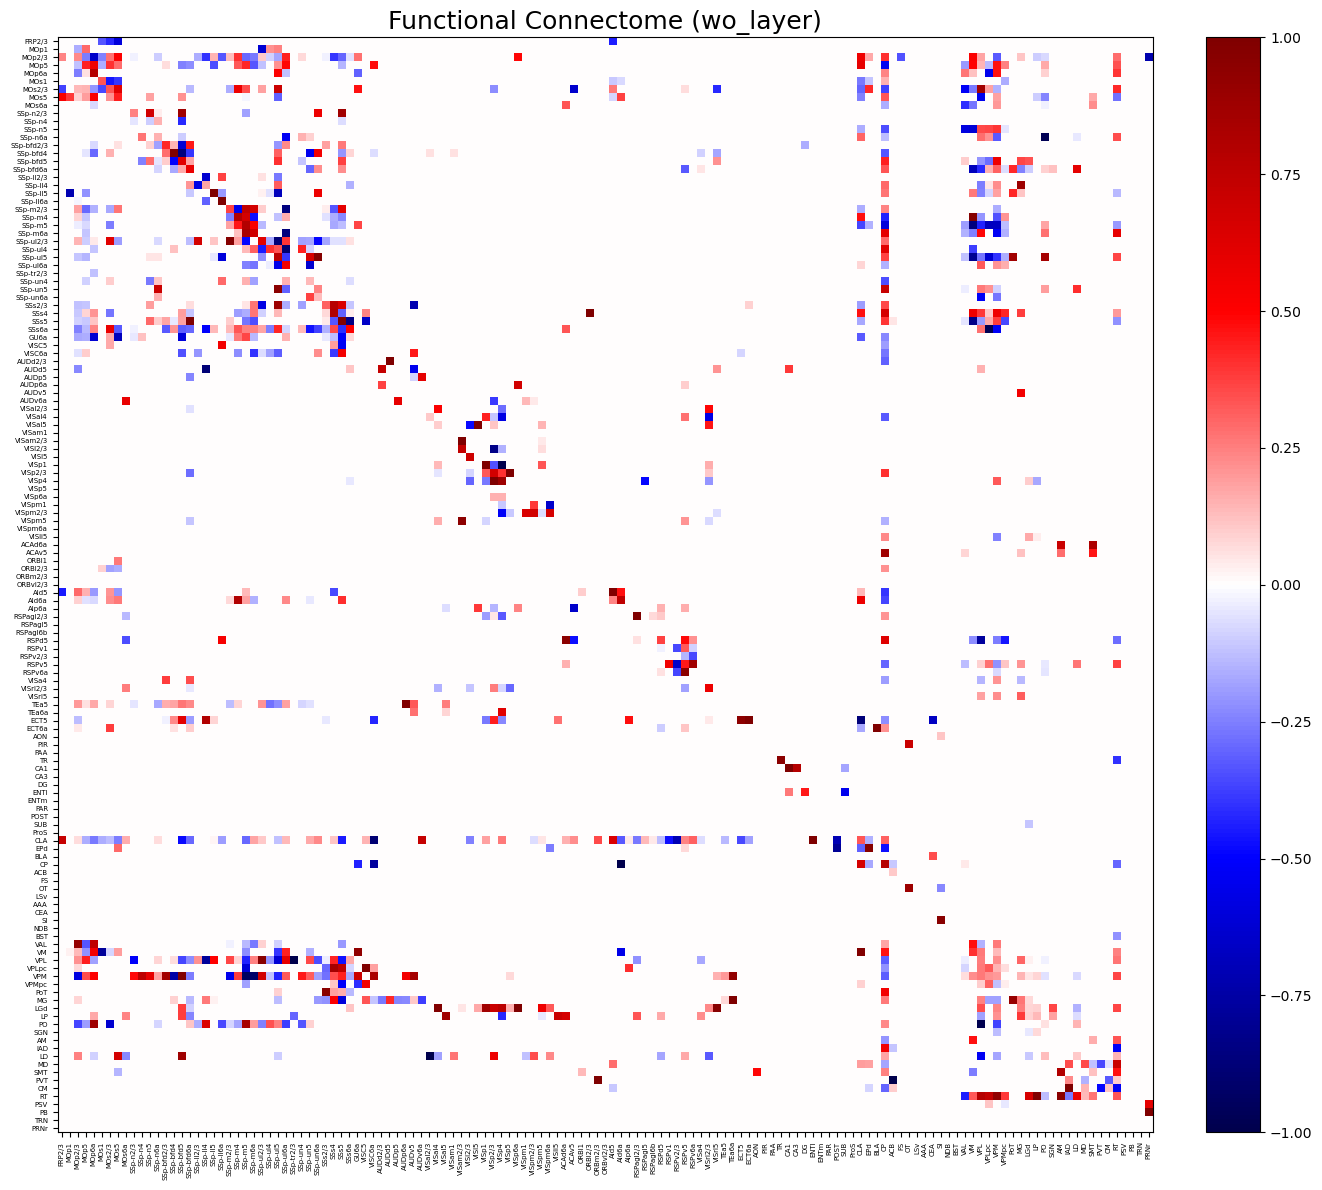

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_1)
df = pd.read_csv(label_path_1)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (wo_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=5)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=5)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_w_layer_stage2.jpg", format="jpg", dpi=300)
plt.show()


## stage3

In [12]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

graph_path_1 = './result/w_layer/stage3/tuning/bs64_dp0.1_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage1/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage3/tuning/bs32_dp0.1_sw0.5/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

def Signed_Strength_Centrality(graph_path, label_path):
    '''
    Signed Strength Centrality
    '''
    graphs = np.load(graph_path)
    labels = pd.read_csv(label_path).iloc[:, 0].values

    pos = np.maximum(graphs, 0).mean(axis=0)
    neg = np.maximum(-graphs, 0).mean(axis=0)

    np.fill_diagonal(pos, 0)
    np.fill_diagonal(neg, 0)

    n = pos.shape[0] - 1

    P_out = pos.sum(axis=1) / n
    N_out = neg.sum(axis=1) / n

    P_in = pos.sum(axis=0) / n
    N_in = neg.sum(axis=0) / n

    C_out = P_out - N_out**2 / (P_out + N_out + 1e-9)
    C_in = P_in - N_in**2 / (P_in + N_in + 1e-9)

    centrality = (C_out + C_in) / 2

    return pd.Series(centrality, index=labels)

mean_dc_1 = Signed_Strength_Centrality(graph_path_1, label_path_1)
mean_dc_2 = Signed_Strength_Centrality(graph_path_2, label_path_2)

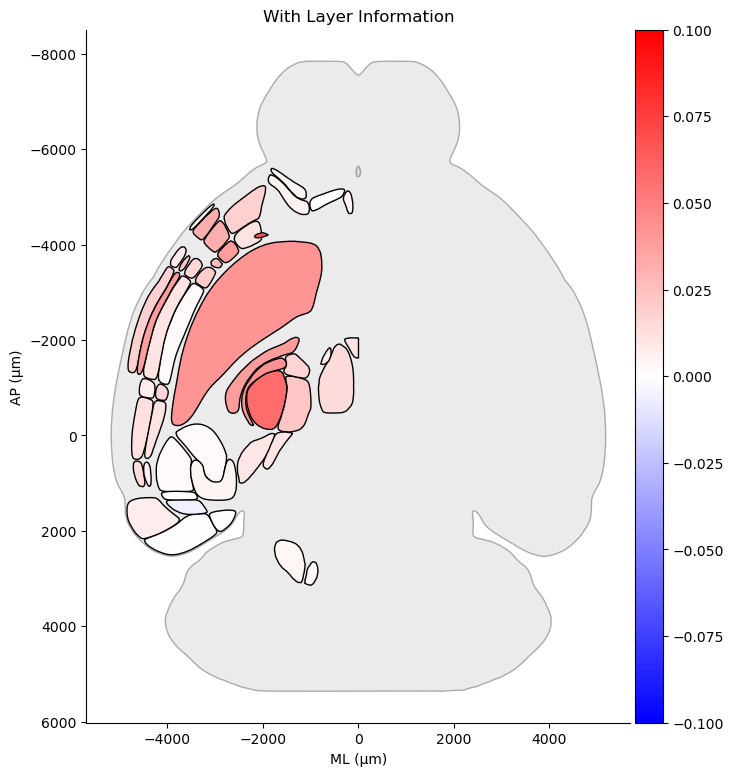

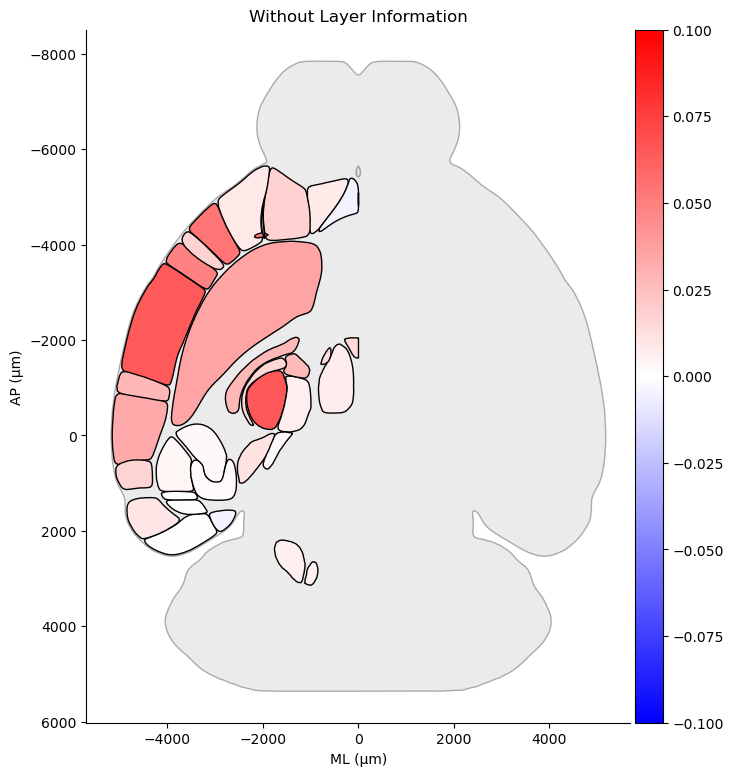

In [13]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh

values1 = mean_dc_1.to_dict()
values2 = mean_dc_2.to_dict()

vmin = -0.1
vmax = 0.1

fig = bgh.Heatmap(
    values=values1,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="With Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

fig = bgh.Heatmap(
    values=values2,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="Without Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')


r = 0.607, p = 1.525e-09, MAE = 0.0106


/tmp/ipykernel_2390752/1611035914.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=25)


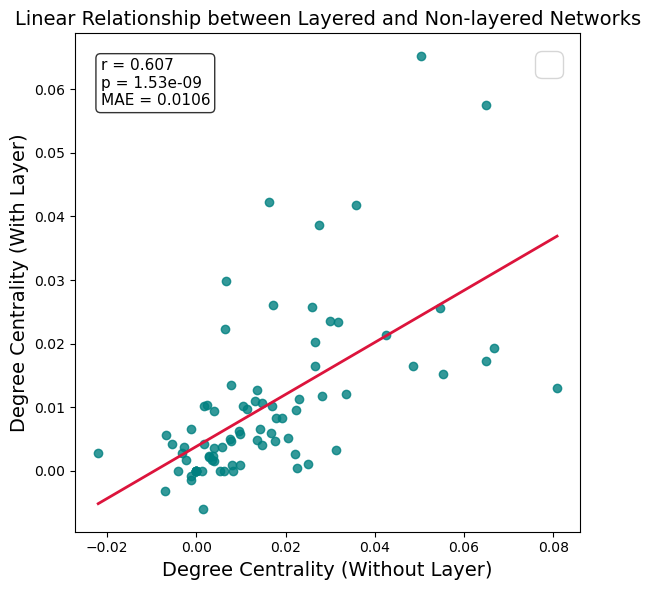

In [14]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import brainglobe_heatmap as bgh
from scipy.stats import linregress

w_layer = mean_dc_1.copy()
wo_layer = mean_dc_2.copy()


def get_base_region(name):
    df = pd.read_csv("../data/region_map.csv", sep="\t")
    region_dict = dict(zip(df.iloc[:,0], df.iloc[:,1]))
    return region_dict.get(name, name)

grouped = {}
for region, val in w_layer.items():
    base = get_base_region(region)
    grouped.setdefault(base, []).append(val)

layer_mean = {base: np.nanmean(vals) for base, vals in grouped.items()}
layer_mean = pd.Series(layer_mean)

common_regions = sorted(set(layer_mean.index) & set(wo_layer.index))
aligned_w = layer_mean[common_regions]
aligned_wo = wo_layer[common_regions]


r, p = pearsonr(aligned_w, aligned_wo)
mae = np.mean(np.abs(aligned_w - aligned_wo))
print(f"r = {r:.3f}, p = {p:.3e}, MAE = {mae:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(aligned_wo, aligned_w, color="teal", alpha=0.8, label="")

slope, intercept, r_val, p_val, stderr = linregress(aligned_wo, aligned_w)

x_fit = np.linspace(aligned_wo.min(), aligned_wo.max(), 100)
y_fit = slope * x_fit + intercept
plt.plot(x_fit, y_fit, color="crimson", linewidth=2, label="")

plt.xlabel("Degree Centrality (Without Layer)", fontsize=14)
plt.ylabel("Degree Centrality (With Layer)", fontsize=14)
plt.title("Linear Relationship between Layered and Non-layered Networks", fontsize=14)

text_str = f"r = {r:.3f}\np = {p:.2e}\nMAE = {mae:.4f}"
plt.text(0.05, 0.95, text_str, transform=plt.gca().transAxes,
         fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.legend(fontsize=25)
plt.grid(alpha=0)
plt.tight_layout()
plt.savefig("./result/fig/scatter_with_vs_without_layer_stage3.png", dpi=300, bbox_inches="tight")

plt.show()


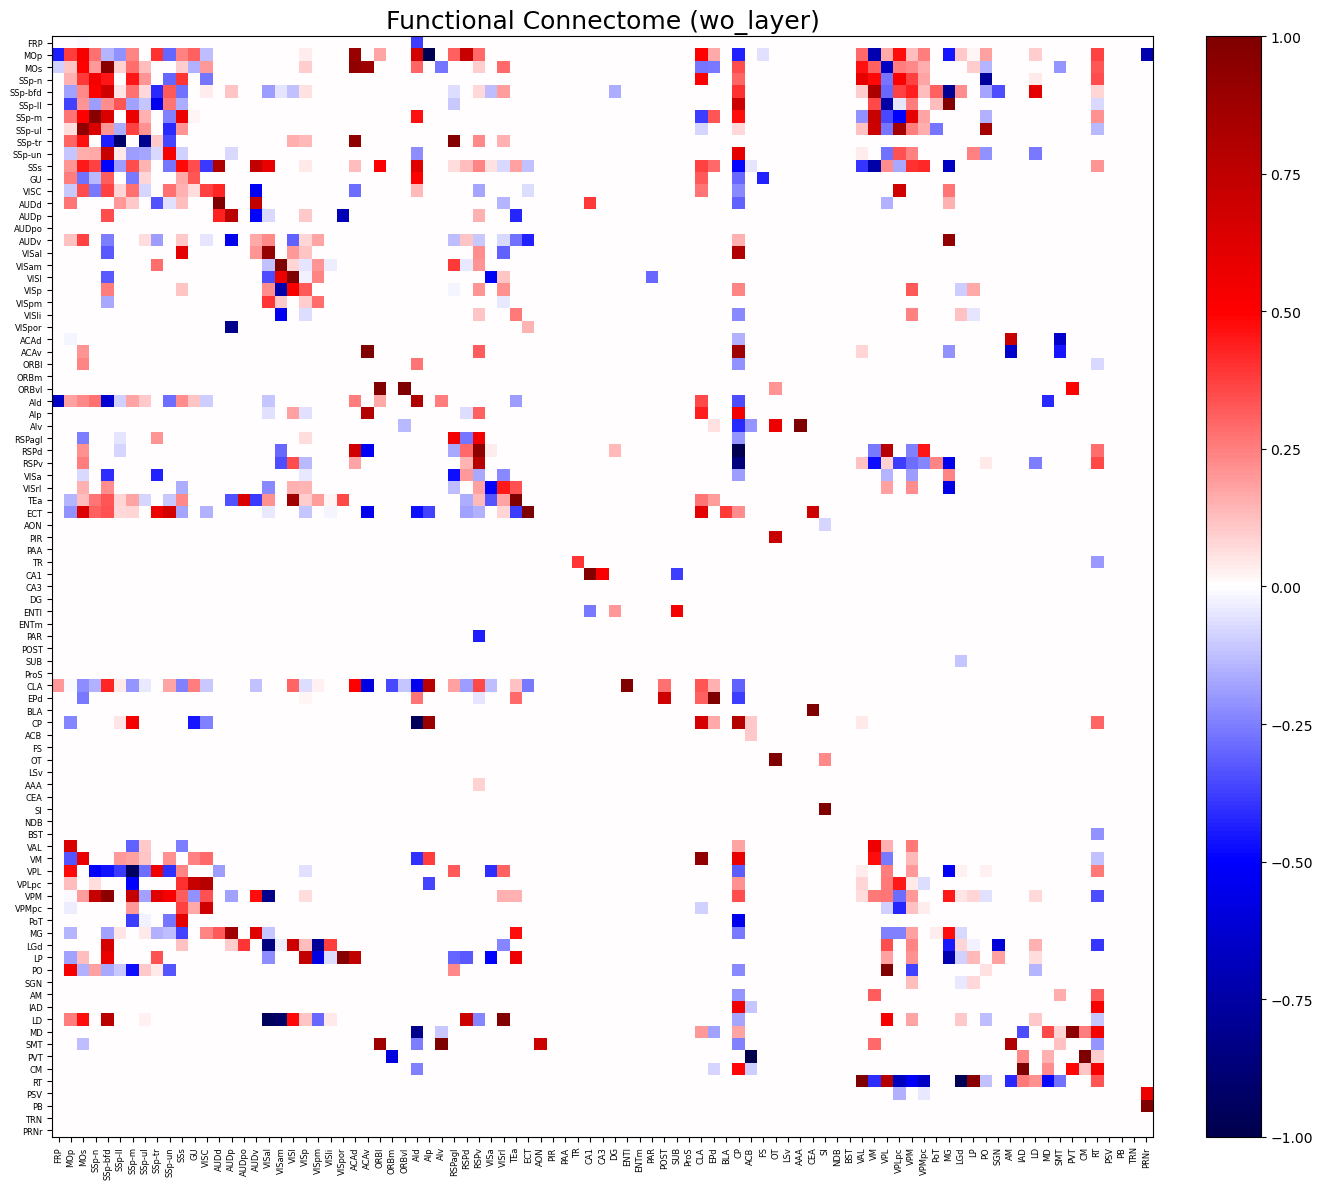

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.family'] = 'DejaVu Sans'
rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_2)
df = pd.read_csv(label_path_2)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (wo_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=6)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=6)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_wo_layer_stage3.jpg", format="jpg", dpi=300)
plt.show()


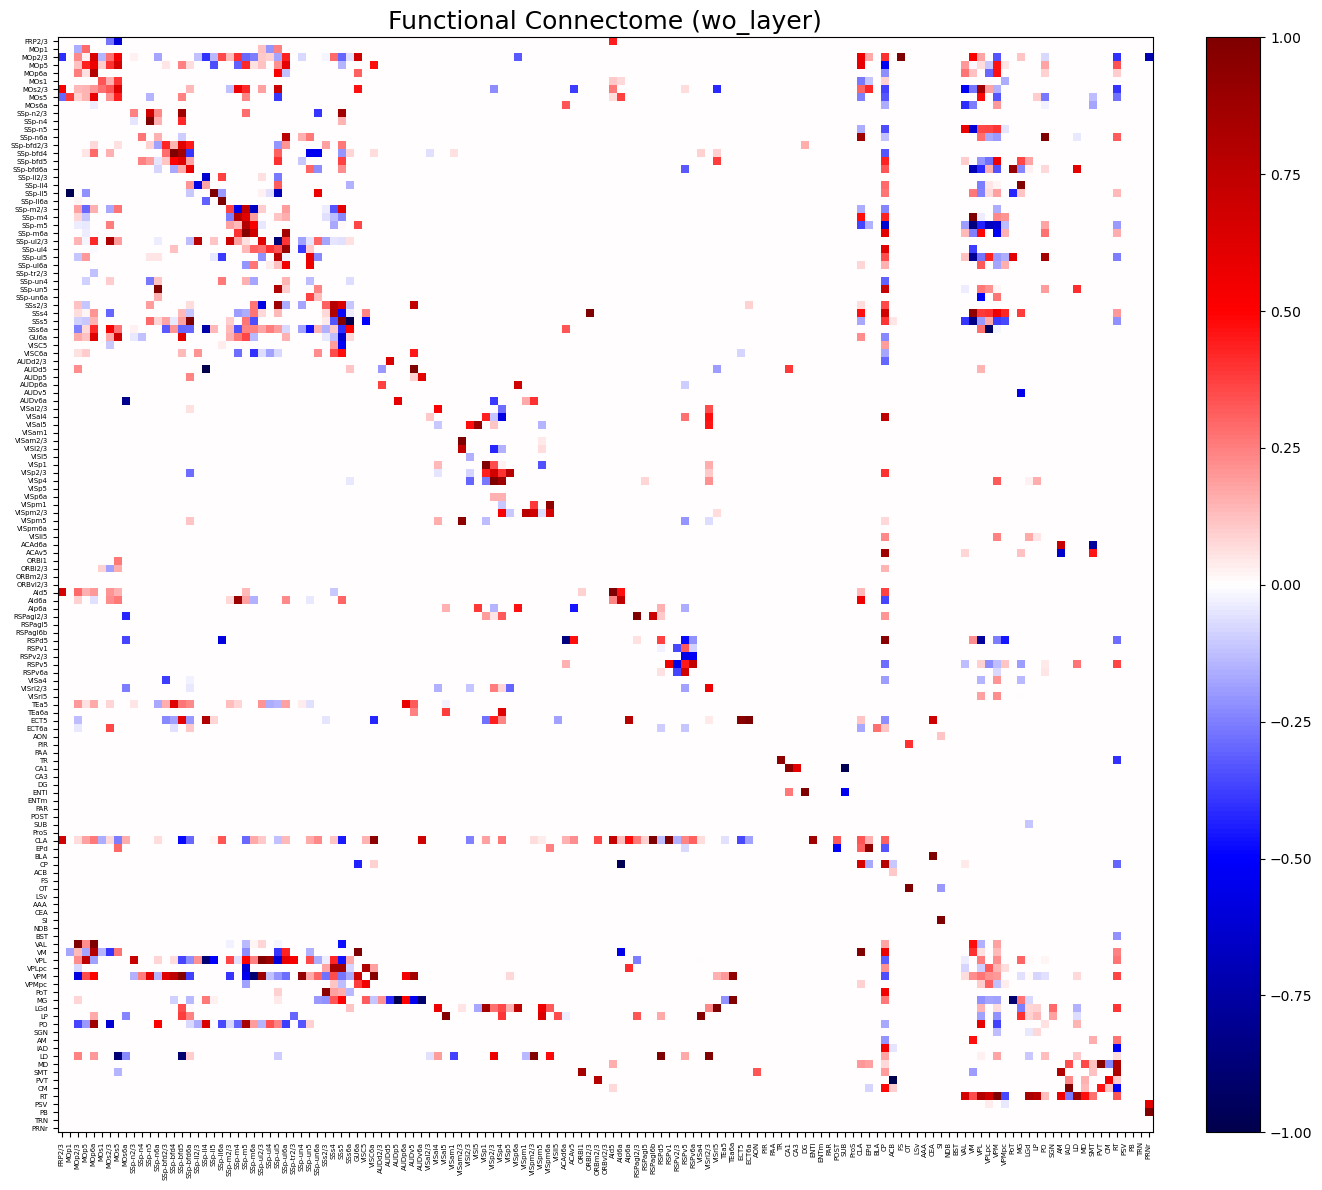

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_1)
df = pd.read_csv(label_path_1)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (wo_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=5)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=5)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_w_layer_stage3.jpg", format="jpg", dpi=300)
plt.show()


## Three stages similarity calculation

### without cortical layer

In [21]:
import numpy as np
import pandas as pd


def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values
    return adj, labels


# paths
stage1_graph_path_2 = './result/wo_layer/stage1/tuning/bs32_dp0.1_sw1.0/dynamic_full_graphs.npy'
stage1_label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

stage2_graph_path_2 = './result/wo_layer/stage2/tuning/bs32_dp0.1_sw1.0/dynamic_full_graphs.npy'
stage2_label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

stage3_graph_path_2 = './result/wo_layer/stage3/tuning/bs32_dp0.1_sw0.5/dynamic_full_graphs.npy'
stage3_label_path_2 = './result/wo_layer/stage1/df_scaled.csv'


A1, L1 = load_mean_adj(stage1_graph_path_2, stage1_label_path_2)
A2, L2 = load_mean_adj(stage2_graph_path_2, stage2_label_path_2)
A3, L3 = load_mean_adj(stage3_graph_path_2, stage3_label_path_2)


# find intersection regions
common = sorted(list(set(L1) & set(L2) & set(L3)))


def reorder(adj, labels, common):
    idx = [np.where(labels == c)[0][0] for c in common]
    return adj[np.ix_(idx, idx)]


A1c = reorder(A1, L1, common)
A2c = reorder(A2, L2, common)
A3c = reorder(A3, L3, common)


def edge_mae(A, B, eps=0, mode="all"):
    if A.shape != B.shape:
        raise ValueError("A and B must have the same shape.")

    n = A.shape[0]

    if mode == "offdiag":
        region_mask = ~np.eye(n, dtype=bool)
    elif mode == "diagonal":
        region_mask = np.eye(n, dtype=bool)
    elif mode == "all":
        region_mask = np.ones((n, n), dtype=bool)
    else:
        raise ValueError("mode must be 'offdiag', 'diagonal', or 'all'.")

    valid_mask = region_mask & (
        (np.abs(A) > eps) | (np.abs(B) > eps)
    )

    if valid_mask.sum() == 0:
        return np.nan

    return np.abs(A[valid_mask] - B[valid_mask]).mean()


mae12 = edge_mae(A1c, A2c)
mae13 = edge_mae(A1c, A3c)
mae23 = edge_mae(A2c, A3c)

print("Intersection brain regions:", len(common))
print("Edge MAE (Stage1 vs Stage2):", round(mae12, 4))
print("Edge MAE (Stage1 vs Stage3):", round(mae13, 4))
print("Edge MAE (Stage2 vs Stage3):", round(mae23, 4))

Intersection brain regions: 89
Edge MAE (Stage1 vs Stage2): 0.151
Edge MAE (Stage1 vs Stage3): 0.165
Edge MAE (Stage2 vs Stage3): 0.1633


In [22]:
from scipy.stats import pearsonr, spearmanr

def edge_corr(A, B, eps=0, mode="offdiag"):
    if A.shape != B.shape:
        raise ValueError("A and B must have the same shape.")

    n = A.shape[0]

    if mode == "offdiag":
        region_mask = ~np.eye(n, dtype=bool)
    elif mode == "diagonal":
        region_mask = np.eye(n, dtype=bool)
    elif mode == "all":
        region_mask = np.ones((n, n), dtype=bool)
    else:
        raise ValueError("mode must be 'offdiag', 'diagonal', or 'all'.")

    valid_mask = region_mask & (
        (np.abs(A) > eps) | (np.abs(B) > eps)
    )

    x = A[valid_mask]
    y = B[valid_mask]

    if len(x) < 2:
        return np.nan, np.nan

    pearson = pearsonr(x, y).statistic
    spearman = spearmanr(x, y).statistic

    return pearson, spearman


# pairwise correlations
p12, s12 = edge_corr(A1c, A2c)
p13, s13 = edge_corr(A1c, A3c)
p23, s23 = edge_corr(A2c, A3c)

print("\nPairwise edge correlations:")
print(f"Stage1 vs Stage2: Pearson={p12:.4f}, Spearman={s12:.4f}")
print(f"Stage1 vs Stage3: Pearson={p13:.4f}, Spearman={s13:.4f}")
print(f"Stage2 vs Stage3: Pearson={p23:.4f}, Spearman={s23:.4f}")


Pairwise edge correlations:
Stage1 vs Stage2: Pearson=0.6007, Spearman=0.5935
Stage1 vs Stage3: Pearson=0.5789, Spearman=0.5513
Stage2 vs Stage3: Pearson=0.5792, Spearman=0.5621


In [23]:
import numpy as np
import pandas as pd
import mpmath as mp
from scipy.stats import pearsonr

mp.mp.dps = 100

# ============================================================
# load learned graphs
# ============================================================
def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)

    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values

    return adj, labels


# ============================================================
# reorder matrix
# ============================================================
def reorder(adj, labels, common):
    labels = np.asarray(labels).astype(str)
    idx = [np.where(labels == c)[0][0] for c in common]
    return adj[np.ix_(idx, idx)]


# ============================================================
# high-precision Pearson p-value
# ============================================================
def pearson_p_mpmath(r, n, digits=30):
    r = mp.mpf(str(abs(r)))
    n = mp.mpf(str(n))

    df = n - 2

    # two-sided p-value for Pearson correlation
    # p = I_{1-r^2}(df/2, 1/2)
    x = 1 - r**2
    p = mp.betainc(df / 2, mp.mpf("0.5"), 0, x, regularized=True)

    return mp.nstr(p, digits, min_fixed=0, max_fixed=0)


# ============================================================
# compare matrices
# ============================================================
def compare_matrix(A,B):
    A,B=np.asarray(A,float),np.asarray(B,float)
    m=~np.eye(A.shape[0],dtype=bool)
    a,b=np.abs(A[m]),np.abs(B[m])
    v=np.isfinite(a)&np.isfinite(b); a,b=a[v],b[v]
    r,_=pearsonr(a,b)
    return {
        "MAE":np.mean(np.abs(a-b)),
        "RMSE":np.sqrt(np.mean((a-b)**2)),
        "Pearson_r":r,
        "Pearson_p":pearson_p_mpmath(r,len(a),digits=3)
    }

# ============================================================
# learned graphs
# ============================================================
stage1_graph_path_2 = './result/wo_layer/stage1/tuning/bs32_dp0.1_sw1.0/dynamic_full_graphs.npy'
stage1_label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

stage2_graph_path_2 = './result/wo_layer/stage2/tuning/bs32_dp0.1_sw1.0/dynamic_full_graphs.npy'
stage2_label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

stage3_graph_path_2 = './result/wo_layer/stage3/tuning/bs32_dp0.1_sw0.5/dynamic_full_graphs.npy'
stage3_label_path_2 = './result/wo_layer/stage1/df_scaled.csv'


# ============================================================
# load learned graphs
# ============================================================
A1, L1 = load_mean_adj(stage1_graph_path_2, stage1_label_path_2)
A2, L2 = load_mean_adj(stage2_graph_path_2, stage2_label_path_2)
A3, L3 = load_mean_adj(stage3_graph_path_2, stage3_label_path_2)


# ============================================================
# load layer matrix
# ============================================================
df_layers = pd.read_excel(
    '../SEU_net_wo_corticalLayers.xlsx',
    header=1,
    index_col=1
)

df_layers = df_layers.iloc[:, 1:]

layer_labels = df_layers.index.astype(str).str.strip().values
A_layer = df_layers.values.astype(float)


# ============================================================
# intersection
# ============================================================
common = sorted(list(set(L1) & set(L2) & set(L3) & set(layer_labels)))

print(f"\nIntersection brain regions: {len(common)}")


# ============================================================
# reorder
# ============================================================
A1c = reorder(A1, L1, common)
A2c = reorder(A2, L2, common)
A3c = reorder(A3, L3, common)
Alc = reorder(A_layer, layer_labels, common)


# ============================================================
# compare
# ============================================================
results = {
    "Stage1_vs_Layer": compare_matrix(A1c, Alc),
    "Stage2_vs_Layer": compare_matrix(A2c, Alc),
    "Stage3_vs_Layer": compare_matrix(A3c, Alc),
}

df_results = pd.DataFrame(results).T


# ============================================================
# print only
# ============================================================
df_print = df_results.copy()

df_print["MAE"] = df_print["MAE"].map(lambda x: f"{x:.4f}")
df_print["RMSE"] = df_print["RMSE"].map(lambda x: f"{x:.4f}")
df_print["Pearson_r"] = df_print["Pearson_r"].map(lambda x: f"{x:.4f}")

print("\nComparison results:")
print(df_print)


Intersection brain regions: 89

Comparison results:
                    MAE    RMSE Pearson_r   Pearson_p
Stage1_vs_Layer  0.1177  0.6517    0.7055  1.26e-1173
Stage2_vs_Layer  0.1169  0.6529    0.6820  2.49e-1066
Stage3_vs_Layer  0.1180  0.6547    0.6876   3.4e-1091


### with cortical layer

In [24]:
import numpy as np
import pandas as pd


def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values
    return adj, labels


# paths
stage1_graph_path_2 = './result/w_layer/stage1/tuning/bs32_dp0.1_sw1.0/dynamic_full_graphs.npy'
stage1_label_path_2 = './result/w_layer/stage1/df_scaled.csv'

stage2_graph_path_2 = './result/w_layer/stage2/tuning/bs16_dp0.1_sw0.7/dynamic_full_graphs.npy'
stage2_label_path_2 = './result/w_layer/stage1/df_scaled.csv'

stage3_graph_path_2 = './result/w_layer/stage3/tuning/bs64_dp0.1_sw0.7/dynamic_full_graphs.npy'
stage3_label_path_2 = './result/w_layer/stage1/df_scaled.csv'


A1, L1 = load_mean_adj(stage1_graph_path_2, stage1_label_path_2)
A2, L2 = load_mean_adj(stage2_graph_path_2, stage2_label_path_2)
A3, L3 = load_mean_adj(stage3_graph_path_2, stage3_label_path_2)


# find intersection regions
common = sorted(list(set(L1) & set(L2) & set(L3)))


def reorder(adj, labels, common):
    idx = [np.where(labels == c)[0][0] for c in common]
    return adj[np.ix_(idx, idx)]


A1c = reorder(A1, L1, common)
A2c = reorder(A2, L2, common)
A3c = reorder(A3, L3, common)


def edge_mae(A, B, eps=0, mode="all"):
    if A.shape != B.shape:
        raise ValueError("A and B must have the same shape.")

    n = A.shape[0]

    if mode == "offdiag":
        region_mask = ~np.eye(n, dtype=bool)
    elif mode == "diagonal":
        region_mask = np.eye(n, dtype=bool)
    elif mode == "all":
        region_mask = np.ones((n, n), dtype=bool)
    else:
        raise ValueError("mode must be 'offdiag', 'diagonal', or 'all'.")

    valid_mask = region_mask & (
        (np.abs(A) > eps) | (np.abs(B) > eps)
    )

    if valid_mask.sum() == 0:
        return np.nan

    return np.abs(A[valid_mask] - B[valid_mask]).mean()


mae12 = edge_mae(A1c, A2c)
mae13 = edge_mae(A1c, A3c)
mae23 = edge_mae(A2c, A3c)

print("Intersection brain regions:", len(common))
print("Edge MAE (Stage1 vs Stage2):", round(mae12, 4))
print("Edge MAE (Stage1 vs Stage3):", round(mae13, 4))
print("Edge MAE (Stage2 vs Stage3):", round(mae23, 4))

Intersection brain regions: 137
Edge MAE (Stage1 vs Stage2): 0.1653
Edge MAE (Stage1 vs Stage3): 0.1636
Edge MAE (Stage2 vs Stage3): 0.1725
